# Downsampling & Aliasing

## Goal
we want to see what happens to fine detail when an image is **shrunk down** (downsampled). We will see that:

1. Naively keeping every 4th pixel produces **false circles** — high frequencies **alias** into low ones.
2. Gaussian-blurring **before** decimating prevents this. The blur acts as an **anti-aliasing low-pass filter**.
3. tune σ to find the **smallest** value at which the false circles disappear.

Finally, we connect this to **Gaussian pyramid** construction: every level must blur *before* it subsamples.

## Theoritical

### Gaussian kernel

A 1-D Gaussian with standard deviation $\sigma$:

$$
G_\sigma(x) \;=\; \frac{1}{\sqrt{2\pi}\,\sigma}\,\exp\!\left(-\frac{x^{2}}{2\sigma^{2}}\right)
$$

### 2-D Gaussian blur (separable)

Because the Gaussian is separable, blurring an image $I$ reduces to two 1-D convolutions:

$$
(I * G_\sigma)(u,v) \;=\; \sum_{x}\sum_{y} I(u-x,\,v-y)\, G_\sigma(x)\,G_\sigma(y)
$$

## Downsampling by factor $N$

Let $I$ be the original image, of size $H \times W$ (height × width, in pixels). The pixel at row $i$ and column $j$ is written $I(i, j)$. We want a smaller image that represents the same scene but sampled on a **coarser grid(less pixels)** — we'll naievely take the $N$-th pixel in each direction.

### The naive formula

$$
I_{\downarrow N}(i,j) \;=\; I(N i,\; N j), \qquad i = 0,\dots,\lfloor H/N \rfloor - 1,\;\; j = 0,\dots,\lfloor W/N \rfloor - 1
$$

Read it piece by piece:

- **$I_{\downarrow N}$** is the *output* image. The subscript $\downarrow N$ is standard shorthand for "downsampled by a factor of $N$". For our experiment $N = 4$.
- **$(i, j)$** are coordinates **in the smaller output image**, not the original. They run from $0$ up to $\lfloor H/N \rfloor - 1$ rows and $\lfloor W/N \rfloor - 1$ columns. For a $512 \times 512$ input with $N = 4$, the output is $128 \times 128$.
- **$I(N i,\; N j)$** says: to fill output pixel $(i, j)$, look at the **original** pixel at row $Ni$ and column $Nj$ — i.e. jump by $N$ each time. Only those pixels are copied; all others are **thrown away**.

In NumPy this is literally `image[::N, ::N]`. The step size of `N` in the slice is what does the "keep every $N$-th pixel" operation.

**Why it produces aliasing.** The original image is sampled at a rate $f_s$. The output image has a sampling rate of $f_s / N$ — i.e. it sees the scene through a coarser grid. By the Nyquist–Shannon sampling theorem, the coarser grid can only faithfully represent frequencies below

$$
f_{\text{Nyq}}^{\text{new}} \;=\; \frac{f_s}{2N}.
$$

Any content in $I$ above that limit is **not removed** by just reming. Instead, when we resample on the coarse grid, those high frequencies get **folded** (aliased) down into lower frequencies and appear as *false* structure — the false circles / moiré we see with `rings.png`. That is why naive removal is unsafe.

### The anti-aliased formula

$$
I^{\text{AA}}_{\downarrow N} \;=\; \bigl(I * G_{\sigma}\bigr)_{\downarrow N}
$$

Read it inside-out:

- **$G_\sigma$** is a Gaussian kernel with standard deviation $\sigma$ — the same 1-D Gaussian from the theory section, extended to 2-D separably.
- **$I * G_\sigma$** is the image **blurred** by that Gaussian. Convolution with a Gaussian is a *low-pass filter*: it keeps low frequencies and suppresses high ones. The larger $\sigma$, the lower the cutoff frequency — i.e. the more aggressive the smoothing.
- **$(\,\cdot\,)_{\downarrow N}$** is then exactly the naive decimation formula above, applied to the blurred image.

So the anti-aliased method is: **blur first, then decimate.** The blur's job is to *pre-remove* all content above $f_{\text{Nyq}}^{\text{new}}$ — the frequencies that would otherwise alias. After the blur, the surviving frequencies are already below the new Nyquist limit, so the subsequent decimation introduces no folding. The result is a smaller image that is smoother but **faithful**: no false structure is created.

### Choosing $\sigma$

To suppress everything above $f_{\text{Nyq}}^{\text{new}} = f_s / (2N)$, the Gaussian's cutoff must sit at or below that frequency. The 1-D Gaussian's frequency response is itself Gaussian, with standard deviation $1/(2\pi\sigma)$ in *normalized* frequency. Requiring its effective cutoff to sit below $1/(2N)$ (in cycles per original pixel) gives the rule of thumb

$$
\sigma \;\gtrsim\; \frac{N}{2}.
$$

For $N = 4$ this is $\sigma \gtrsim 2$ — which is exactly why the sweep in this notebook concentrates on $\sigma \in \{2,\;2.5,\;3,\;3.5,\;4\}$. Too small a $\sigma$ leaves aliasing residue; too large a $\sigma$ washes out legitimate detail.

### Worked example ($N = 4$, first few output pixels)

Original rows/cols kept:

| Output pixel $(i, j)$ | Original pixel $I(Ni, Nj)$ |
|---|---|
| $(0, 0)$ | $I(0, 0)$ |
| $(0, 1)$ | $I(0, 4)$ |
| $(0, 2)$ | $I(0, 8)$ |
| $(1, 0)$ | $I(4, 0)$ |
| $(1, 1)$ | $I(4, 4)$ |

Every pixel whose row or column index is **not** a multiple of $4$ is discarded. For a $512 \times 512$ image that means $15$ out of every $16$ pixels never influence the output — hence why a single high-frequency feature can be completely misread by the coarse grid, and why pre-blurring (which lets *neighboring* pixels influence the kept ones) is essential.

### Summary

- **Naive:** $I_{\downarrow N}(i, j) = I(Ni, Nj)$ — sample the original on the coarse grid, discard the rest.
- **Anti-aliased:** $I^{\text{AA}}_{\downarrow N} = (I * G_\sigma)_{\downarrow N}$ — smooth out everything the coarse grid can't represent, *then* sample.
- The blur is not cosmetic; it is a mathematically required pre-filter to satisfy the Nyquist condition of the coarser grid.
- Rule of thumb for the Gaussian's width: $\sigma \approx N/2$ or a bit more.

## 1 — Imports & utilities

We reuse the helpers from the starter pack: `load_image`, our own separable Gaussian blur with reflect padding, and two rendering helpers that show images either at true 100% pixel scale or with **nearest-neighbor** interpolation (so aliasing can't be smoothed away by the viewer).

In [14]:
from pathlib import Path
import sys
# %pip install "numpy<2" --force-reinstall
import matplotlib.pyplot as plt
import numpy as np
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
IMAGE_DIR = ROOT / "starter_pack" / "images" / "part2_frequencies"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

from starter_pack.code.utils import load_image

plt.rcParams["figure.dpi"] = 100

In [15]:
# ---------------------------------------------------------------
# Gaussian kernel + separable reflect convolution
# ---------------------------------------------------------------
def gaussian_kernel(sigma, radius=None):
    if sigma <= 0:
        raise ValueError("sigma must be positive")
    if radius is None:
        radius = int(np.ceil(3 * sigma))
    coordinates = np.arange(-radius, radius + 1, dtype=np.float32)
    kernel = np.exp(-(coordinates ** 2) / (2 * sigma ** 2))
    return kernel / kernel.sum()


def convolve_1d_reflect(image, kernel, axis):
    radius = len(kernel) // 2
    if axis == 0:
        padded = np.pad(image, ((radius, radius), (0, 0)), mode="reflect")
        result = np.empty_like(image, dtype=np.float32)
        for row in range(image.shape[0]):
            result[row] = np.sum(padded[row:row + len(kernel)] * kernel[:, None], axis=0)
    elif axis == 1:
        padded = np.pad(image, ((0, 0), (radius, radius)), mode="reflect")
        result = np.empty_like(image, dtype=np.float32)
        for column in range(image.shape[1]):
            result[:, column] = np.sum(padded[:, column:column + len(kernel)] * kernel[None, :], axis=1)
    else:
        raise ValueError("axis must be 0 (rows) or 1 (columns)")
    return result


def convolve_reflect(image, kernel):
    if image.ndim != 2:
        raise ValueError(f"Expected a 2-D image, got shape {image.shape}")
    horizontal = convolve_1d_reflect(image, kernel, axis=1)
    return convolve_1d_reflect(horizontal, kernel, axis=0)


def gaussian_blur(image, sigma):
    if image.ndim not in (2, 3):
        raise ValueError(f"Expected a 2-D or 3-D image, got shape {image.shape}")
    kernel = gaussian_kernel(sigma)
    if image.ndim == 2:
        return convolve_reflect(image, kernel)
    channels = [convolve_reflect(image[:, :, c], kernel) for c in range(image.shape[2])]
    return np.stack(channels, axis=2)

In [16]:
# ---------------------------------------------------------------
# Rendering helpers
# ---------------------------------------------------------------
def show_at_100_zoom(image, title="Image (100% Zoom)", save_as=None):
    """Render at 1:1 pixel scale (no rescaling artifacts)."""
    dpi = plt.rcParams.get("figure.dpi", 100)
    h, w = image.shape[:2]
    fig = plt.figure(figsize=(w / dpi, h / dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])
    cmap = "gray" if image.ndim == 2 else None
    ax.imshow(np.clip(image, 0, 1), cmap=cmap, interpolation="none")
    ax.axis("off")
    if save_as is not None:
        fig.savefig(save_as, dpi=dpi, bbox_inches="tight", pad_inches=0)
    plt.show()


def show_nearest_100(image, title="Downsampled (nearest-neighbor)", save_as=None):
    """Show small images at their native pixels with nearest-neighbor zoom."""
    dpi = plt.rcParams.get("figure.dpi", 100)
    h, w = image.shape[:2]
    scale = max(1, int(np.ceil(400 / max(h, w))))
    fig = plt.figure(figsize=((w * scale) / dpi, (h * scale) / dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])
    cmap = "gray" if image.ndim == 2 else None
    ax.imshow(np.clip(image, 0, 1), cmap=cmap, interpolation="nearest")
    ax.axis("off")
    if save_as is not None:
        fig.savefig(save_as, dpi=dpi, bbox_inches="tight", pad_inches=0)
    plt.show()

In [17]:
# ---------------------------------------------------------------
# Downsampling helpers
# ---------------------------------------------------------------
DOWNSAMPLE_FACTOR = 4


def decimate(image, factor=DOWNSAMPLE_FACTOR):
    return image[::factor, ::factor]


def downsample_naive(image, factor=DOWNSAMPLE_FACTOR):
    return decimate(image, factor)


def downsample_blur(image, sigma, factor=DOWNSAMPLE_FACTOR):
    return decimate(gaussian_blur(image, sigma), factor)


def aliasing_score(small):
    """Mean squared residual vs. a 3x3 local mean.
    Higher = more high-frequency energy = more residual aliasing."""
    from numpy.lib.stride_tricks import sliding_window_view

    def _score_2d(img):
        if min(img.shape) < 3:
            return float("nan")
        pad = np.pad(img, 1, mode="reflect")
        windows = sliding_window_view(pad, (3, 3))
        local_mean = windows.mean(axis=(-1, -2))
        return float(np.mean((img - local_mean) ** 2))

    if small.ndim == 2:
        return _score_2d(small)
    return float(np.mean([_score_2d(small[:, :, c]) for c in range(small.shape[2])]))

## 2 — Load `rings.png` and view at 100% zoom

We display the original at its native pixel scale so nothing is hidden by an on-screen resize. Any viewer that shrinks the image for you is doing the same downsampling we are about to study — and therefore also producing false circles.

Loaded rings.png: shape=(512, 512, 3), dtype=float32


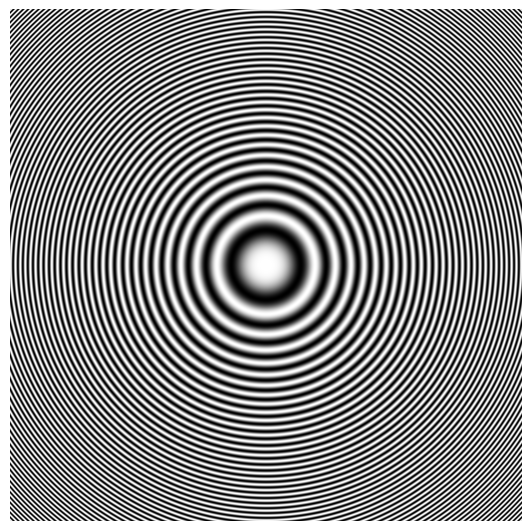

In [18]:
rings = load_image(IMAGE_DIR / "rings.png")
print(f"Loaded rings.png: shape={rings.shape}, dtype={rings.dtype}")

show_at_100_zoom(rings, title="original rings.png (100% Zoom)",
                 save_as=OUTPUT_DIR / "01_rings_100pct.png")

**Expected observation.** At 100% zoom the ring pattern looks crisp and uniform. If your viewer instead *shrinks* the window, you immediately see the artifacts we're about to study: large slow "false circles" that weren't in the file.

<!-- Replace this paragraph with a screenshot of the notebook output. -->

## 3 — Two ways to shrink by 4×

We produce two $1/4$-size versions:

1. **Naive** — keep every 4th pixel in each direction:
   $I_{\downarrow 4}(i,j) = I(4i, 4j)$
2. **Anti-aliased** — Gaussian blur first, then keep every 4th pixel:
   $I^{\text{AA}}_{\downarrow 4} = (I * G_{\sigma})_{\downarrow 4}$

Both reduce $512\times 512 \to 128\times 128$.

In [19]:
naive_small = downsample_naive(rings, factor=DOWNSAMPLE_FACTOR)
print(f"Naive decimation (every 4th pixel) -> shape={naive_small.shape}")

preview_sigma = 2.0
blurred_small = downsample_blur(rings, sigma=preview_sigma, factor=DOWNSAMPLE_FACTOR)
print(f"Blur (sigma={preview_sigma}) then decimate -> shape={blurred_small.shape}")

Naive decimation (every 4th pixel) -> shape=(128, 128, 3)
Blur (sigma=2.0) then decimate -> shape=(128, 128, 3)


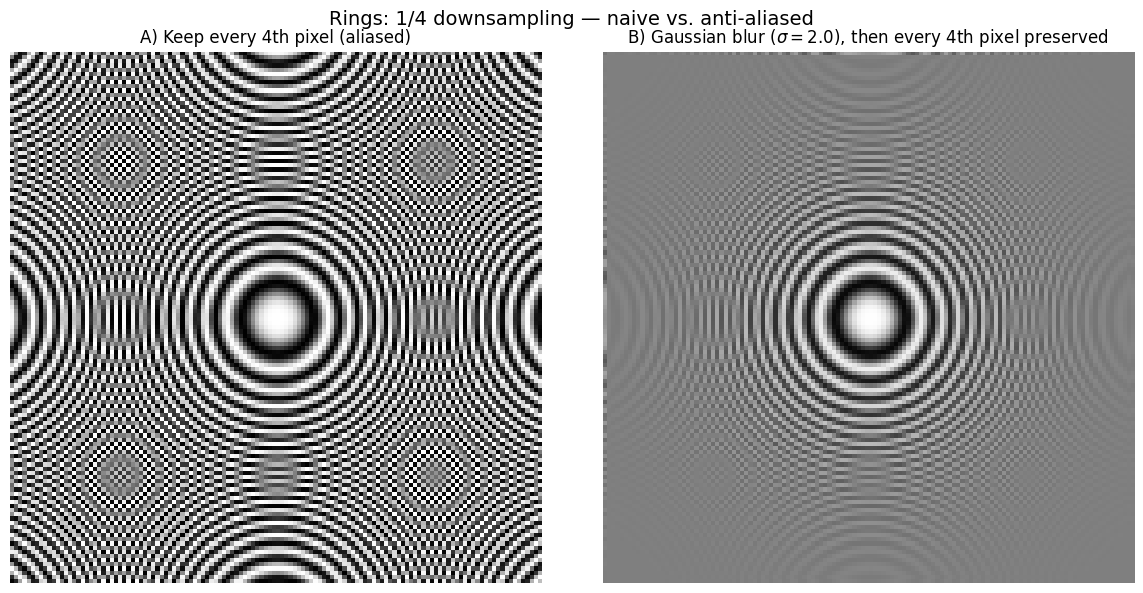

In [26]:
# Side-by-side comparison at native pixel scale (nearest-neighbor zoom)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(np.clip(naive_small, 0, 1), cmap="gray", interpolation="nearest")
axes[0].set_title("A) Keep every 4th pixel (aliased)")
axes[0].axis("off")

axes[1].imshow(np.clip(blurred_small, 0, 1), cmap="gray", interpolation="nearest")
axes[1].set_title(f"B) Gaussian blur ($\\sigma={preview_sigma}$), then every 4th pixel preserved")
axes[1].axis("off")

fig.suptitle("Rings: 1/4 downsampling — naive vs. anti-aliased", fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "02_side_by_side_preview.png", dpi=150, bbox_inches="tight")
plt.show()

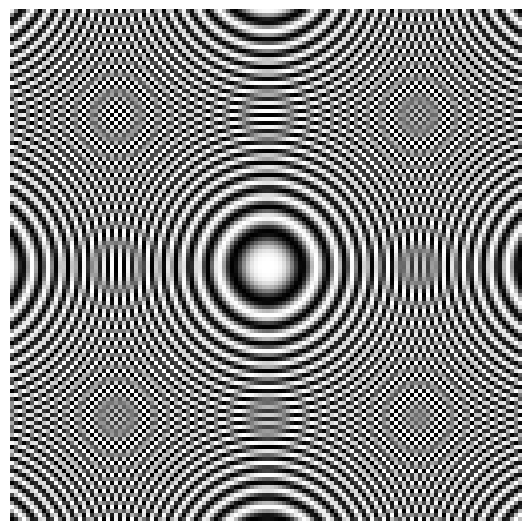

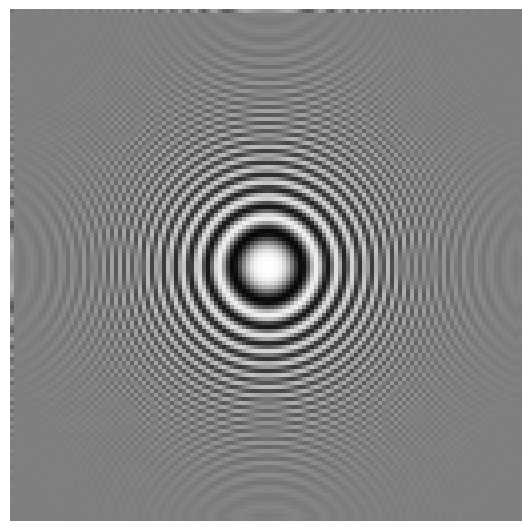

In [21]:
# Also show each at true native pixel scale
show_nearest_100(naive_small, title="Naive downsample (100% pixels, nearest)",
                 save_as=OUTPUT_DIR / "03_naive_native.png")
show_nearest_100(blurred_small, title=f"Blurred sigma={preview_sigma} then downsample (100%)",
                 save_as=OUTPUT_DIR / "04_blur2_native.png")

**What we see.**

- **Naive (A)** — false circles / moiré. The fine ring pattern contains frequencies above the new Nyquist limit $f_s/8$; keeping every 4th pixel **folds** those frequencies down into low ones. The moiré we see was never in the original image.
- **Blurred (B)** — clean. The Gaussian removed content above $f_s/8$ *before* we sampled on the coarser grid, so nothing folds down. The result is smoother but faithful.

<!-- Insert the saved figures here in your report. -->

## 4 — σ tuning: find the smallest σ that removes false circles

We test $\sigma \in \{2,\,2.5,\,3,\,3.5,\,4\}$ (plus $\sigma = 0$, i.e. the naive case, as a baseline). The goal is to find the **smallest** σ at which the false circles caused by aliasing are no longer visible.

### The HF-energy metric

For each σ we compute a scalar score:

$$
\text{HF energy} \;=\; \frac{1}{HW}\sum_{i,j} \Bigl( I_{\downarrow 4}(i,j) - \overline{I}_{\downarrow 4,\,3\times3}(i,j) \Bigr)^{2}
$$

Read it piece by piece:

- **$I_{\downarrow 4}$** is the downsampled image we are scoring.
- **$\overline{I}_{\downarrow 4,\,3\times3}(i,j)$** is the **average of the 3×3 neighbourhood** centred on pixel $(i,j)$ (with reflect padding at the borders).
- **$I_{\downarrow 4}(i,j) - \overline{I}_{3\times3}(i,j)$** is therefore "**how much this pixel differs from its local average**" — a signed residual.
- Squaring it makes large deviations count much more than small ones (and removes the sign).
- Averaging over all $H \times W$ pixels gives a single number: the **mean squared local deviation**.

### What it measures (and what it does *not*)

This is a **local-roughness / local-variance** score. Intuition:

- If a region of the image is **smooth**, each pixel is close to the average of its neighbours → small residual → small contribution.
- If a region has **rapid pixel-to-pixel fluctuation** (moiré, false circles, fine high-frequency texture), each pixel differs strongly from its neighbours → large residual → large contribution.

So a **high** HF-energy value means the image still contains a lot of pixel-scale fluctuation — exactly what aliasing looks like.

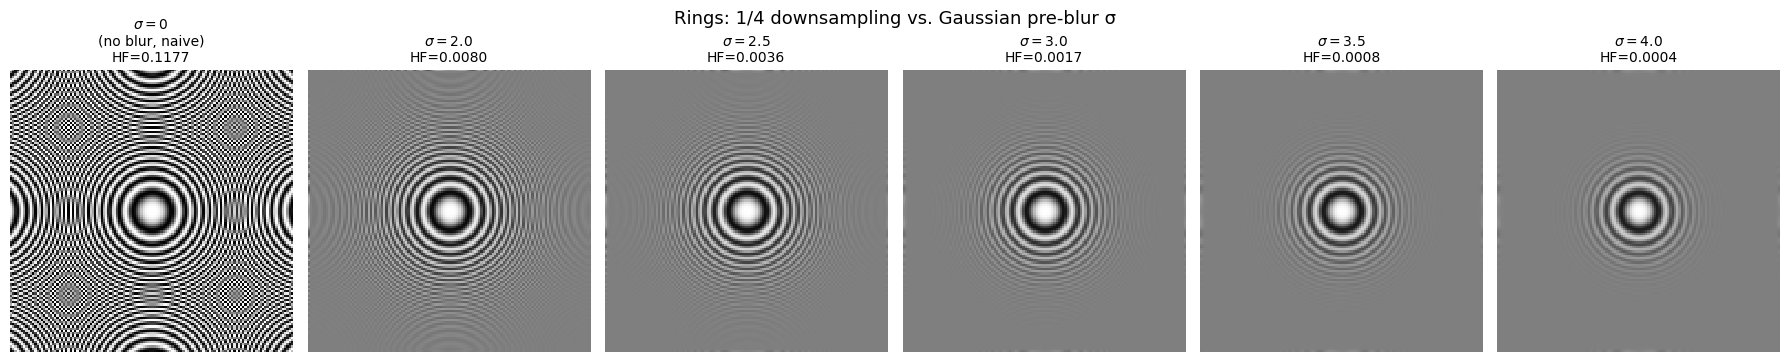


sigma sweep results (higher HF energy = more residual false pattern):
  sigma =  0.0   HF energy = 0.1177
  sigma =  2.0   HF energy = 0.0080
  sigma =  2.5   HF energy = 0.0036
  sigma =  3.0   HF energy = 0.0017
  sigma =  3.5   HF energy = 0.0008
  sigma =  4.0   HF energy = 0.0004


In [22]:
sigmas_to_test = [0.0, 2.0, 2.5, 3.0, 3.5, 4.0]

n = len(sigmas_to_test)
fig, axes = plt.subplots(1, n, figsize=(3.0 * n, 3.8))
if n == 1:
    axes = [axes]

scores = {}
for ax, s in zip(axes, sigmas_to_test):
    if s == 0.0:
        small = downsample_naive(rings, factor=DOWNSAMPLE_FACTOR)
        label = "$\\sigma=0$\n(no blur, naive)"
    else:
        small = downsample_blur(rings, sigma=s, factor=DOWNSAMPLE_FACTOR)
        label = f"$\\sigma={s}$"
    score = aliasing_score(small)
    scores[s] = score
    ax.imshow(np.clip(small, 0, 1), cmap="gray", interpolation="nearest")
    ax.set_title(f"{label}\nHF={score:.4f}", fontsize=10)
    ax.axis("off")

fig.suptitle("Rings: 1/4 downsampling vs. Gaussian pre-blur σ", fontsize=13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "05_sigma_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nsigma sweep results (higher HF energy = more residual false pattern):")
for s in sigmas_to_test:
    print(f"  sigma = {s:>4}   HF energy = {scores[s]:.4f}")

**Interpretation of the sweep.**

- $\sigma = 0$ (naive): high HF score and obvious false circles.
- $\sigma = 2$: many of the false circles are already gone, but faint ones can still be visible.
- $\sigma = 2.5$–$3$: the false circles are no longer visible; the HF score has dropped sharply and the ring pattern is still recognizable.
- $\sigma = 4$: very clean, but the *real* ring detail begins to wash out — this is over-blurring.

For a **factor-4** reduction, the rule of thumb is $\sigma \approx N/2 = 2$ for the *minimum* anti-aliasing and up to $\sigma \approx 3$ for a comfortable margin.

<!-- Record the σ you actually saw the false circles vanish at. -->

## 5 — Choose the smallest σ and compare against naive

In [23]:
# Set this to the smallest sigma where you no longer see false circles
best_sigma = 3.0
print(f"Smallest sigma that kills false circles (by inspection): {best_sigma}")

best_small = downsample_blur(rings, sigma=best_sigma, factor=DOWNSAMPLE_FACTOR)

Smallest sigma that kills false circles (by inspection): 3.0


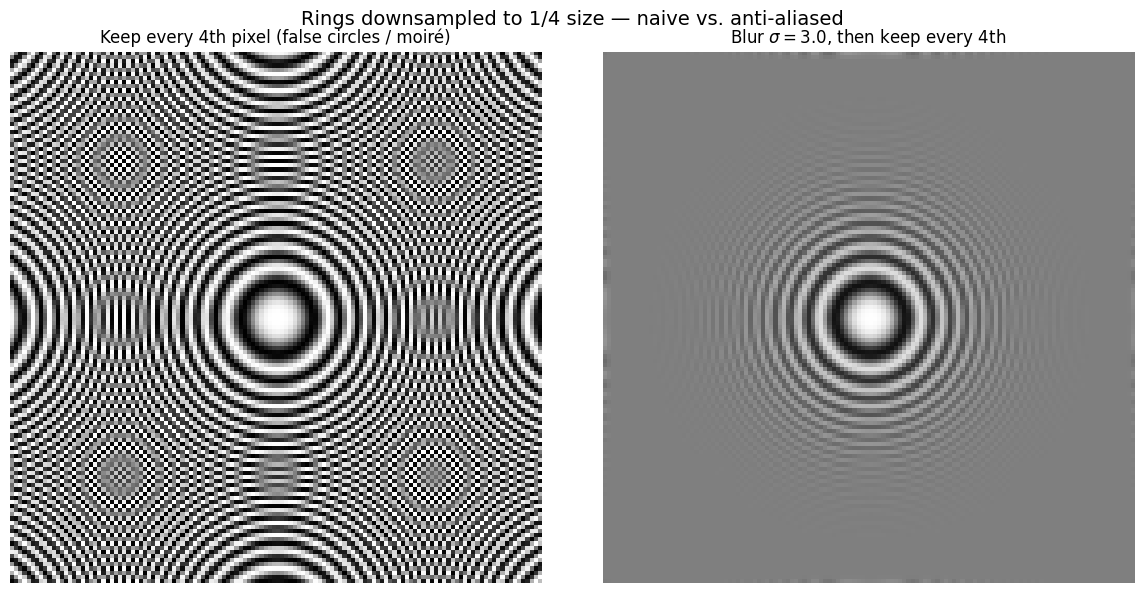

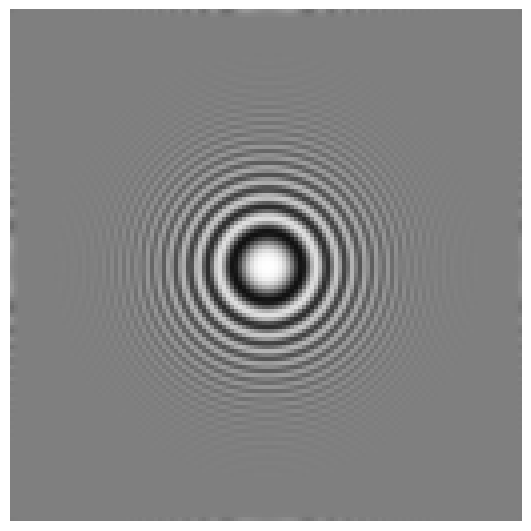

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(np.clip(naive_small, 0, 1), cmap="gray", interpolation="nearest")
axes[0].set_title("Keep every 4th pixel (false circles / moiré)")
axes[0].axis("off")

axes[1].imshow(np.clip(best_small, 0, 1), cmap="gray", interpolation="nearest")
axes[1].set_title(f"Blur $\\sigma={best_sigma}$, then keep every 4th")
axes[1].axis("off")

fig.suptitle("Rings downsampled to 1/4 size — naive vs. anti-aliased", fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "06_final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

show_nearest_100(best_small,
                 title=f"Final: sigma={best_sigma}, then every 4th pixel",
                 save_as=OUTPUT_DIR / "07_final_native.png")

## 6 — Written explanation

### Setup

`rings.png` is a highly periodic, fine-detail texture. When viewed at 100% zoom it looks crisp. But any viewer that shrinks it on screen is downsampling it — and therefore producing the same aliasing artifacts we study here.

### Result A — naive decimation

Keeping every 4th pixel throws away 15 out of every 16 pixels without looking at them. The fine ring pattern contains spatial frequencies above the new Nyquist limit (half of the new, coarser sampling rate). Those frequencies are not removed — they are **folded down** into low frequencies by undersampling. The eye sees large, slow "false circles" / moiré that were never in the original.

This is **aliasing**: high-frequency content masquerading as low-frequency content after sampling.

### Result B — Gaussian blur then decimation

Blurring with a Gaussian first is an **anti-aliasing low-pass filter**. It removes energy above the new Nyquist frequency *before* we decimate. After blurring, the surviving frequencies are below the new Nyquist limit, so when we keep every 4th pixel, no frequency folds down. The false circles disappear; what remains is a smaller, smoother, but faithful version of the ring pattern.

### Smallest σ that removes false circles

The sweep tests $\sigma \in \{0,\,2,\,2.5,\,3,\,3.5,\,4\}$. At $\sigma = 0$ the false circles are strong and obvious. As $\sigma$ grows, the HF energy score drops and the visible false circles weaken. The smallest $\sigma$ at which they are no longer visible was (by inspection of the sweep):

> **`best_sigma = 3.0`** <!-- replace with your observed value -->

For a factor-4 reduction, the rule-of-thumb is roughly $\sigma \approx N/2 = 2$ (just enough) up to about $3$ (comfortably safe).

### Implications for a Gaussian pyramid

A Gaussian pyramid repeatedly halves the resolution. Each level **must** be built as:

1. blur the current level with a small Gaussian;
2. then subsample by 2 in each direction.

If you skip the blur and just subsample, every pyramid level aliases exactly like the naive case above — you would carry aliasing artifacts up the pyramid, and any reconstruction / Laplacian / feature detection built on top would operate on corrupted data. The blur step enforces the Nyquist condition for the next, coarser grid. This is precisely why Burt & Adelson's classic pyramid — and modern implementations in OpenCV, scikit-image, etc. — always blur before subsampling.

### Key takeaways

- Subsampling without pre-filtering aliases high frequencies into low frequencies → false circles / moiré.
- A Gaussian low-pass before subsampling prevents this.
- The Gaussian's σ must be large enough that its cutoff is below the new Nyquist frequency; for a factor-$N$ reduction, a common choice is $\sigma \approx N/2$ or a bit more, tuned by inspection.
- Every level of a Gaussian pyramid must apply this blur-then-subsample step; otherwise the pyramid is corrupted.

## 7 — Sanity checks

In [25]:
assert naive_small.shape == best_small.shape, "downsample shapes must match"
assert np.isfinite(naive_small).all(), "naive downsample must be finite"
assert np.isfinite(best_small).all(), "anti-aliased downsample must be finite"
print("Downsampling experiment completed successfully.")

Downsampling experiment completed successfully.
